# MALTO Workshop 2026
## Workshop 2: Transformer Architectures, Part 2

**Topic:** write the attention layer, the Transformer block and a small GPT model. Then look at the attention weights of real trained models.

Part 1 of the notebook showed how a text becomes a sequence of vectors: tokenization, embedding and positional encoding. This part starts from these vectors.

Each component is short: a few lines of **NumPy**, then the same component in **PyTorch**.

| Section | Component |
|---|---|
| 4 | Attention in NumPy |
| 5 | Scaled dot-product attention |
| 6 | Causal mask |
| 7 | Self-attention and cross-attention |
| 8 | Multi-head attention |
| 9 | Transformer block |
| 10 | A small GPT model |
| 11 | Attention maps of GPT-2 and BERT |

**Names in the code:**

| Name | Symbol | Meaning |
|---|---|---|
| `n_tokens` | $n$ | number of tokens |
| `d_model` | $d$ | size of each token vector |
| `d_k`, `d_v` | $d_k$, $d_v$ | size of each query and key, size of each value |
| `n_heads` | $h$ | number of heads |
| `token_vectors` | $H$ | one row for each token |
| `queries`, `keys`, `values` | $Q$, $K$, $V$ | |
| `W_query`, `W_key`, `W_value` | $W^Q$, $W^K$, $W^V$ | learned matrices |
| `attention_weights` | $A$ | one row for each query, each row sums to 1 |

## 0. Setup

A GPU is not necessary. Section 11 downloads GPT-2 and BERT from Hugging Face (about 1 GB).

In [1]:
!pip -q install bertviz tiktoken

In [2]:
import math
import os
import shutil

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

rng = np.random.default_rng(42)
torch.manual_seed(42)
np.set_printoptions(precision=2, suppress=True)

FIGURE_DIR = "figures"            # all the figures are saved here as PNG
os.makedirs(FIGURE_DIR, exist_ok=True)


def show_matrix(matrix, row_labels, col_labels, title, ax=None, numbers=True):
    # Draw a matrix as a heatmap. Rows: queries. Columns: keys.
    if ax is None:
        fig, ax = plt.subplots(figsize=(0.7 * len(col_labels) + 2, 0.5 * len(row_labels) + 1.5))
    shown = np.where(np.isinf(matrix), np.nan, matrix)          # -inf is drawn as an empty cell
    ax.imshow(shown, cmap="Blues")
    ax.set_xticks(range(len(col_labels)), col_labels, rotation=60)
    ax.set_yticks(range(len(row_labels)), row_labels)
    ax.set_title(title)
    if numbers:
        for i in range(len(row_labels)):
            for j in range(len(col_labels)):
                value = matrix[i][j]
                text = "-inf" if np.isinf(value) else f"{value:.2f}"
                color = "white" if value > 0.6 * np.nanmax(shown) else "black"
                ax.text(j, i, text, ha="center", va="center", fontsize=8, color=color)


def save_figure(fig, name):
    fig.savefig(os.path.join(FIGURE_DIR, name + ".png"), dpi=300, bbox_inches="tight")

## 4. Attention in NumPy

Each output of an attention layer is a weighted sum of the values: $out_i = \sum_j \alpha_{ij} v_j$. The weights $\alpha_{ij}$ come from the comparison of query $i$ with all the keys.

### 4.1 Q, K and V

Three tokens (dog, food, it), vectors with 2 numbers. In a real model, the token vectors come from the embeddings and the matrices $W^Q$, $W^K$, $W^V$ are learned in training. Here we choose them.

Each row is one token. Thus row $i$ of $Q = H W^Q$ is the query of token $i$.

In [3]:
tokens = ["dog", "food", "it"]

token_vectors = np.array([[1.0, 1.0],     # dog
                          [0.0, 1.0],     # food
                          [1.0, 0.0]])    # it

W_query = np.array([[1.0, 1.0],
                    [0.0, 1.0]])
W_key = np.array([[1.0, 0.0],
                  [1.0, 1.0]])
W_value = np.array([[2.0, 0.0],
                    [0.0, 1.0]])

queries = token_vectors @ W_query     # Q = H W^Q, one query for each token
keys = token_vectors @ W_key          # K = H W^K, one key for each token
values = token_vectors @ W_value      # V = H W^V, one value for each token

print("queries:\n", queries)
print("keys:\n", keys)
print("values:\n", values)

queries:
 [[1. 2.]
 [0. 1.]
 [1. 1.]]
keys:
 [[2. 1.]
 [1. 1.]
 [1. 0.]]
values:
 [[2. 1.]
 [0. 1.]
 [2. 0.]]


### 4.2 The `attention` function

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(QK^T / \sqrt{d_k}\right) V$$

| Step | Operation | Shape |
|---|---|---|
| 1. Scores | $QK^T$: each query against each key | $(n_q, n_k)$ |
| 2. Scale | divide by $\sqrt{d_k}$ (Section 5) | $(n_q, n_k)$ |
| 3. Mask | add $M$: 0 keeps a score, $-\infty$ removes it (Section 6) | $(n_q, n_k)$ |
| 4. Weights | softmax on each row: each row sums to 1 | $(n_q, n_k)$ |
| 5. Output | weights × values: a weighted sum of the values | $(n_q, d_v)$ |

In [4]:
def softmax(scores):
    exp_scores = np.exp(scores - scores.max(axis=-1, keepdims=True))   # subtract the max: no overflow
    return exp_scores / exp_scores.sum(axis=-1, keepdims=True)         # each row sums to 1


def attention(queries, keys, values, mask=None, scale=True):
    d_k = queries.shape[-1]
    scores = queries @ keys.T                     # 1. scores
    if scale:
        scores = scores / np.sqrt(d_k)            # 2. scale
    if mask is not None:
        scores = scores + mask                    # 3. mask
    attention_weights = softmax(scores)           # 4. weights
    output = attention_weights @ values           # 5. output
    return output, attention_weights

Here without the scale, to see the plain attention. Read the figure from left to right.

For example, the query of "it" gives the scores 3, 2, 1. The softmax changes them into the weights 0.67, 0.24, 0.09. Thus the output of "it" is $0.67\,v_{dog} + 0.24\,v_{food} + 0.09\,v_{it}$: it takes mostly the information of "dog".

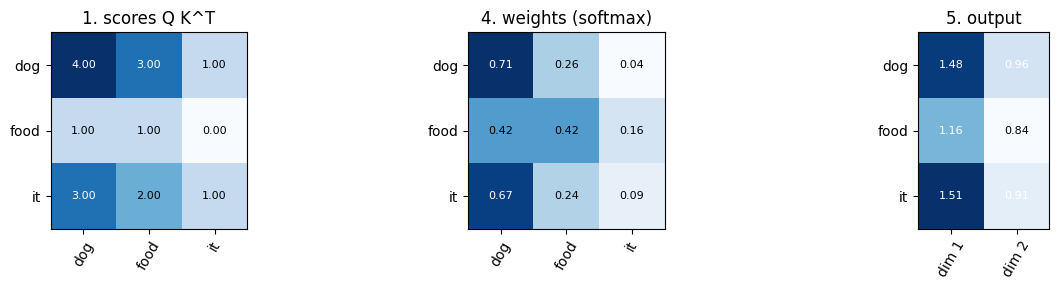

In [5]:
output, attention_weights = attention(queries, keys, values, scale=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
show_matrix(queries @ keys.T, tokens, tokens, "1. scores Q K^T", ax=axes[0])
show_matrix(attention_weights, tokens, tokens, "4. weights (softmax)", ax=axes[1])
show_matrix(output, tokens, ["dim 1", "dim 2"], "5. output", ax=axes[2])
plt.tight_layout()
plt.show()

## 5. Scaled dot-product attention

With large vectors, the dot products $q \cdot k$ are large. Then the softmax gives almost all the weight to one key. The division by $\sqrt{d_k}$ keeps the scores small.

### 5.1 The small example, with the scale

In [6]:
_, weights_without_scale = attention(queries, keys, values, scale=False)
_, weights_with_scale = attention(queries, keys, values, scale=True)

print("weights of 'it' without the scale:", weights_without_scale[2])
print("weights of 'it' with the scale:   ", weights_with_scale[2])

weights of 'it' without the scale: [0.67 0.24 0.09]
weights of 'it' with the scale:    [0.58 0.28 0.14]


### 5.2 With large vectors

One query and 10 keys with $d_k = 64$, as in the Transformer. Without the scale, one key takes almost all the weight. With the scale, the weights are spread over more keys.

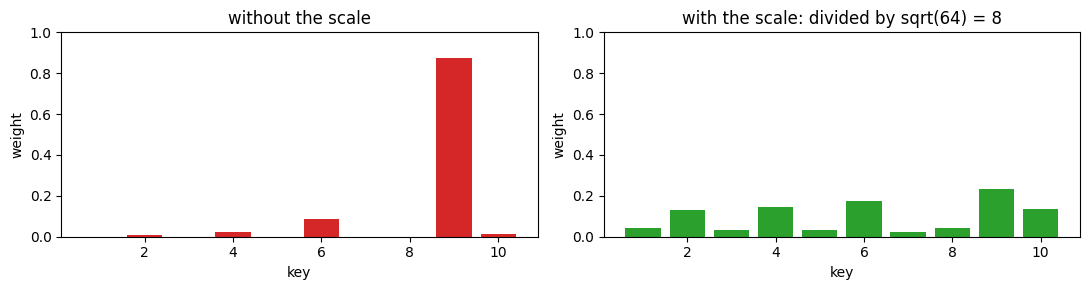

In [7]:
d_k = 64
query = rng.normal(size=(1, d_k))
keys_64 = rng.normal(size=(10, d_k))
values_64 = rng.normal(size=(10, d_k))

_, without_scale = attention(query, keys_64, values_64, scale=False)
_, with_scale = attention(query, keys_64, values_64, scale=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].bar(range(1, 11), without_scale[0], color="C3")
axes[0].set_title("without the scale")
axes[1].bar(range(1, 11), with_scale[0], color="C2")
axes[1].set_title("with the scale: divided by sqrt(64) = 8")
for ax in axes:
    ax.set_xlabel("key")
    ax.set_ylabel("weight")
    ax.set_ylim(0, 1)
plt.tight_layout()
save_figure(fig, "scaled_attention")
plt.show()

### 5.3 In PyTorch

PyTorch has the same function: `F.scaled_dot_product_attention`. It divides by $\sqrt{d_k}$ by default. PyTorch works with batches of sequences, thus we add one dimension at the start.

In [8]:
def to_torch(matrix):
    return torch.tensor(matrix, dtype=torch.float32).unsqueeze(0)    # (n, d) -> (1, n, d)

output_torch = F.scaled_dot_product_attention(to_torch(queries), to_torch(keys), to_torch(values))
print(output_torch)

tensor([[[1.3886, 0.9257],
         [1.1978, 0.8022],
         [1.4320, 0.8600]]])


## 6. Causal mask

When a model writes a text, it writes one token at a time. Thus position $i$ must not look at the next positions. The mask $M$ puts $-\infty$ on the scores with the next positions. After the softmax, $\exp(-\infty) = 0$: these positions get weight 0.

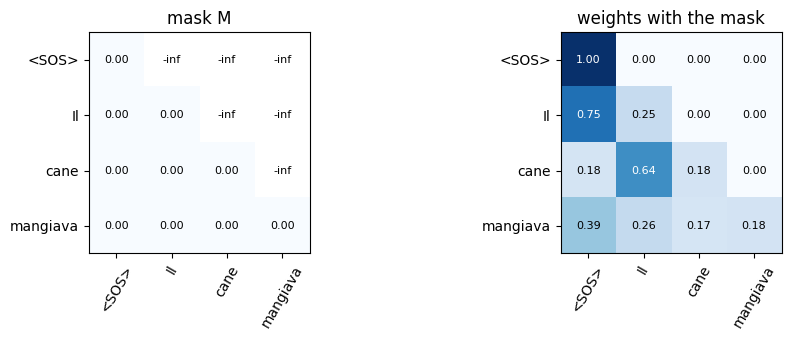

In [9]:
def causal_mask(n_tokens):
    mask = np.zeros((n_tokens, n_tokens))
    mask[np.triu_indices(n_tokens, k=1)] = -np.inf     # -inf above the diagonal: the next positions
    return mask


decoder_tokens = ["<SOS>", "Il", "cane", "mangiava"]
n_tokens, d_model = len(decoder_tokens), 8

token_vectors = rng.normal(size=(n_tokens, d_model))          # random vectors, only for the example
W_query, W_key, W_value = (rng.normal(size=(d_model, d_model)) / np.sqrt(d_model) for _ in range(3))

mask = causal_mask(n_tokens)
_, weights_masked = attention(token_vectors @ W_query, token_vectors @ W_key, token_vectors @ W_value, mask=mask)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
show_matrix(mask, decoder_tokens, decoder_tokens, "mask M", ax=axes[0])
show_matrix(weights_masked, decoder_tokens, decoder_tokens, "weights with the mask", ax=axes[1])
plt.tight_layout()
save_figure(fig, "causal_mask")
plt.show()

In PyTorch, one argument adds the mask: `is_causal=True`.

In [10]:
output_torch = F.scaled_dot_product_attention(to_torch(token_vectors @ W_query),
                                              to_torch(token_vectors @ W_key),
                                              to_torch(token_vectors @ W_value),
                                              is_causal=True)
print(output_torch.shape)

torch.Size([1, 4, 8])


## 7. Self-attention and cross-attention

The attention function is always the same. Only the inputs change:

- **Self-attention:** $Q$, $K$ and $V$ come from the same sentence.
- **Cross-attention:** $Q$ comes from the decoder, $K$ and $V$ come from the encoder.

Example: translation of "The dog was eating" into Italian. The decoder has 3 positions, the encoder has 4 tokens. The result has one row for each query: 3 rows.

weights: (3, 4) | output: (3, 8)


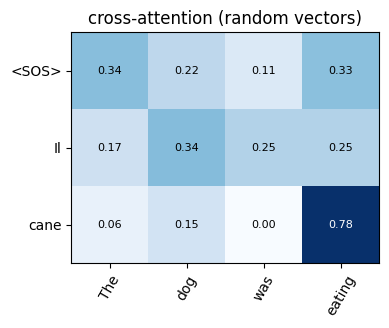

In [11]:
encoder_tokens = ["The", "dog", "was", "eating"]     # English sentence
decoder_tokens = ["<SOS>", "Il", "cane"]             # Italian translation, so far

encoder_vectors = rng.normal(size=(4, d_model))      # random vectors, only for the example
decoder_vectors = rng.normal(size=(3, d_model))

queries = decoder_vectors @ W_query                  # from the DECODER
keys = encoder_vectors @ W_key                       # from the ENCODER
values = encoder_vectors @ W_value                   # from the ENCODER

output, cross_weights = attention(queries, keys, values)
print("weights:", cross_weights.shape, "| output:", output.shape)

show_matrix(cross_weights, decoder_tokens, encoder_tokens, "cross-attention (random vectors)")
plt.show()

## 8. Multi-head attention

Each head is a separate attention with its own part of $W^Q$, $W^K$, $W^V$. With $d_{model} = 16$ and 4 heads, each head uses 4 columns of each matrix. At the end, the outputs of the heads are put side by side (concatenation) and multiplied by $W^O$.

### 8.1 In NumPy

input: (11, 16) | output: (11, 16)


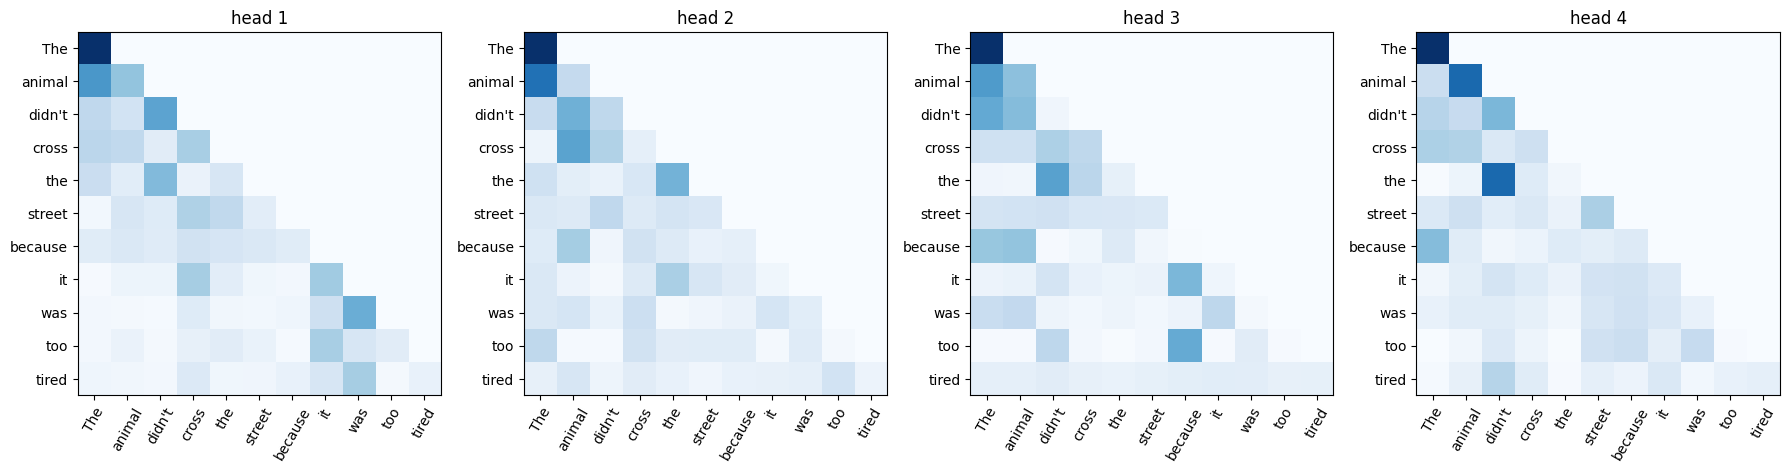

In [12]:
def multi_head_attention(token_vectors, W_query, W_key, W_value, W_output, n_heads, mask=None):
    d_model = token_vectors.shape[1]
    d_head = d_model // n_heads
    head_outputs, head_weights = [], []

    for head in range(n_heads):
        columns = slice(head * d_head, (head + 1) * d_head)      # the columns of this head
        queries = token_vectors @ W_query[:, columns]
        keys = token_vectors @ W_key[:, columns]
        values = token_vectors @ W_value[:, columns]
        output, weights = attention(queries, keys, values, mask=mask)
        head_outputs.append(output)
        head_weights.append(weights)

    concatenated = np.concatenate(head_outputs, axis=1)          # heads side by side: (n_tokens, d_model)
    return concatenated @ W_output, head_weights


sentence = "The animal didn't cross the street because it was too tired".split()
n_tokens, d_model, n_heads = len(sentence), 16, 4

token_vectors = rng.normal(size=(n_tokens, d_model))             # random vectors, only for the example
W_query, W_key, W_value, W_output = (rng.normal(size=(d_model, d_model)) / np.sqrt(d_model) for _ in range(4))

output, head_weights = multi_head_attention(token_vectors, W_query, W_key, W_value, W_output,
                                            n_heads, mask=causal_mask(n_tokens))
print("input:", token_vectors.shape, "| output:", output.shape)

fig, axes = plt.subplots(1, n_heads, figsize=(4.5 * n_heads, 4.5))
for head in range(n_heads):
    show_matrix(head_weights[head], sentence, sentence, f"head {head + 1}", ax=axes[head], numbers=False)
plt.tight_layout()
plt.show()

The model is not trained, thus these weights have no meaning yet. Section 11 shows the weights of trained models.

### 8.2 In PyTorch

The same layer as a PyTorch module. Here all the heads are computed at the same time: `view` and `transpose` separate the heads, and `F.scaled_dot_product_attention` does the attention of all the heads together.

In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.W_query = nn.Linear(d_model, d_model)
        self.W_key = nn.Linear(d_model, d_model)
        self.W_value = nn.Linear(d_model, d_model)
        self.W_output = nn.Linear(d_model, d_model)

    def forward(self, x):
        batch_size, n_tokens, d_model = x.shape
        d_head = d_model // self.n_heads

        # (batch, tokens, d_model) -> (batch, heads, tokens, d_head)
        queries = self.W_query(x).view(batch_size, n_tokens, self.n_heads, d_head).transpose(1, 2)
        keys = self.W_key(x).view(batch_size, n_tokens, self.n_heads, d_head).transpose(1, 2)
        values = self.W_value(x).view(batch_size, n_tokens, self.n_heads, d_head).transpose(1, 2)

        output = F.scaled_dot_product_attention(queries, keys, values, is_causal=True)

        # (batch, heads, tokens, d_head) -> (batch, tokens, d_model): heads side by side
        output = output.transpose(1, 2).reshape(batch_size, n_tokens, d_model)
        return self.W_output(output)


attention_layer = MultiHeadAttention(d_model=16, n_heads=4)
x = torch.randn(2, 11, 16)                 # 2 sentences, 11 tokens, d_model = 16
print("input:", x.shape, "-> output:", attention_layer(x).shape)

input: torch.Size([2, 11, 16]) -> output: torch.Size([2, 11, 16])


## 9. Transformer block

### 9.1 Layer normalization

LayerNorm normalizes each token separately: for each row, subtract the mean and divide by the standard deviation. Then each row has mean 0 and variance 1.

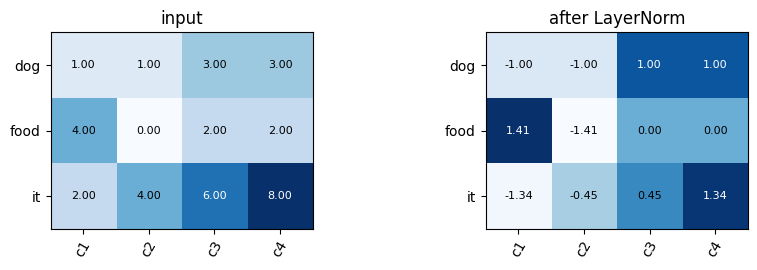

In [14]:
def layer_norm(x, eps=1e-5):
    mean = x.mean(axis=-1, keepdims=True)            # one mean for each token (row)
    std = np.sqrt(x.var(axis=-1, keepdims=True) + eps)
    return (x - mean) / std


table = np.array([[1.0, 1.0, 3.0, 3.0],
                  [4.0, 0.0, 2.0, 2.0],
                  [2.0, 4.0, 6.0, 8.0]])

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
show_matrix(table, ["dog", "food", "it"], ["c1", "c2", "c3", "c4"], "input", ax=axes[0])
show_matrix(layer_norm(table), ["dog", "food", "it"], ["c1", "c2", "c3", "c4"], "after LayerNorm", ax=axes[1])
plt.tight_layout()
plt.show()

### 9.2 The block

A block has two parts. Each part has a LayerNorm and a residual connection: the input is added to the output (`x = x + ...`), thus the token keeps its vector and adds new information.

1. Multi-head attention: the tokens exchange information.
2. Feed-forward network: a small MLP (Workshop 1) on each token. Hidden size $4 \cdot d_{model}$.

We put the LayerNorm at the input of each part, as GPT-2 does.

In [15]:
class Block(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        self.norm_1 = nn.LayerNorm(d_model)
        self.attention = MultiHeadAttention(d_model, n_heads)
        self.norm_2 = nn.LayerNorm(d_model)
        self.feed_forward = nn.Sequential(
            nn.Linear(d_model, 4 * d_model),
            nn.GELU(),
            nn.Linear(4 * d_model, d_model),
        )

    def forward(self, x):
        x = x + self.attention(self.norm_1(x))       # part 1 + residual connection
        x = x + self.feed_forward(self.norm_2(x))    # part 2 + residual connection
        return x


block = Block(d_model=16, n_heads=4)
print("input:", x.shape, "-> output:", block(x).shape)

input: torch.Size([2, 11, 16]) -> output: torch.Size([2, 11, 16])


The output has the same shape as the input. Thus we can put many blocks one after the other.

## 10. A small GPT model

The complete model:

1. token embedding + position embedding (Part 1);
2. $N$ blocks;
3. a last LayerNorm;
4. the output head: a linear layer that gives one score (logit) for each token of the vocabulary. The softmax of the logits gives the probability of the next token.

In [16]:
class GPT(nn.Module):
    def __init__(self, vocab_size, max_tokens, d_model, n_heads, n_blocks):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_tokens, d_model)
        self.blocks = nn.Sequential(*[Block(d_model, n_heads) for _ in range(n_blocks)])
        self.final_norm = nn.LayerNorm(d_model)
        self.output_head = nn.Linear(d_model, vocab_size)

    def forward(self, token_ids):
        positions = torch.arange(token_ids.shape[1])
        x = self.token_embedding(token_ids) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.final_norm(x)
        return self.output_head(x)         # logits: one score for each token of the vocabulary

We use the GPT-2 tokenizer of Part 1 and a small model. At each position, the model must predict the next token. The model is not trained (Workshop 3 trains it), thus here we only look at the shapes.

In [17]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
model = GPT(vocab_size=tokenizer.n_vocab, max_tokens=64, d_model=64, n_heads=4, n_blocks=2)

text = "The animal didn't cross the street because it was too tired."
token_ids = torch.tensor([tokenizer.encode(text)])
inputs, targets = token_ids[:, :-1], token_ids[:, 1:]          # the target is the next token

for i, t in zip(inputs[0].tolist(), targets[0].tolist()):
    print(f"{tokenizer.decode([i])!r:10s} -> {tokenizer.decode([t])!r}")

logits = model(inputs)
print("\ninputs:", inputs.shape, "-> logits:", logits.shape, "(batch, tokens, vocabulary)")

'The'      -> ' animal'
' animal'  -> ' didn'
' didn'    -> "'t"
"'t"       -> ' cross'
' cross'   -> ' the'
' the'     -> ' street'
' street'  -> ' because'
' because' -> ' it'
' it'      -> ' was'
' was'     -> ' too'
' too'     -> ' tired'
' tired'   -> '.'

inputs: torch.Size([1, 12]) -> logits: torch.Size([1, 12, 50257]) (batch, tokens, vocabulary)


## 11. Attention maps of GPT-2 and BERT

Now the weights of trained models, on the same sentence for both models.

- **GPT-2** (decoder only): each token sees only itself and the tokens before it.
- **BERT** (encoder only): each token sees all the tokens.

How to read a map: row $i$ shows where token $i$ looks. Dark cell = large weight. Many heads put a large weight on the first token or on the special tokens `[CLS]` and `[SEP]` (Clark et al., 2019; Xiao et al., 2024). A large weight shows where a head takes information, not why the model makes a prediction (Jain and Wallace, 2019).

In [18]:
from transformers import AutoModel, AutoTokenizer

sentence = "The animal didn't cross the street because it was too tired."


def get_attentions(model_name, sentence):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name, attn_implementation="eager")
    inputs = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)
    tokens = [t.replace("Ġ", "") for t in tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])]
    return tokens, outputs.attentions          # one tensor for each layer: (1, heads, tokens, tokens)


def show_all_heads(attentions, title, file_name):
    n_layers, n_heads = len(attentions), attentions[0].shape[1]
    fig, axes = plt.subplots(n_layers, n_heads, figsize=(1.7 * n_heads, 1.7 * n_layers))
    for layer in range(n_layers):
        for head in range(n_heads):
            ax = axes[layer, head]
            ax.imshow(attentions[layer][0, head], cmap="Blues")
            ax.set_xticks([])
            ax.set_yticks([])
            if layer == 0:
                ax.set_title(f"head {head + 1}")
            if head == 0:
                ax.set_ylabel(f"layer {layer + 1}")
    fig.suptitle(title, fontsize=16)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    save_figure(fig, file_name)
    plt.show()

### 11.1 GPT-2

All the 144 heads: 12 layers (rows) and 12 heads (columns). All the maps are triangular, because of the causal mask.

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

['The', 'animal', 'didn', "'t", 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.']


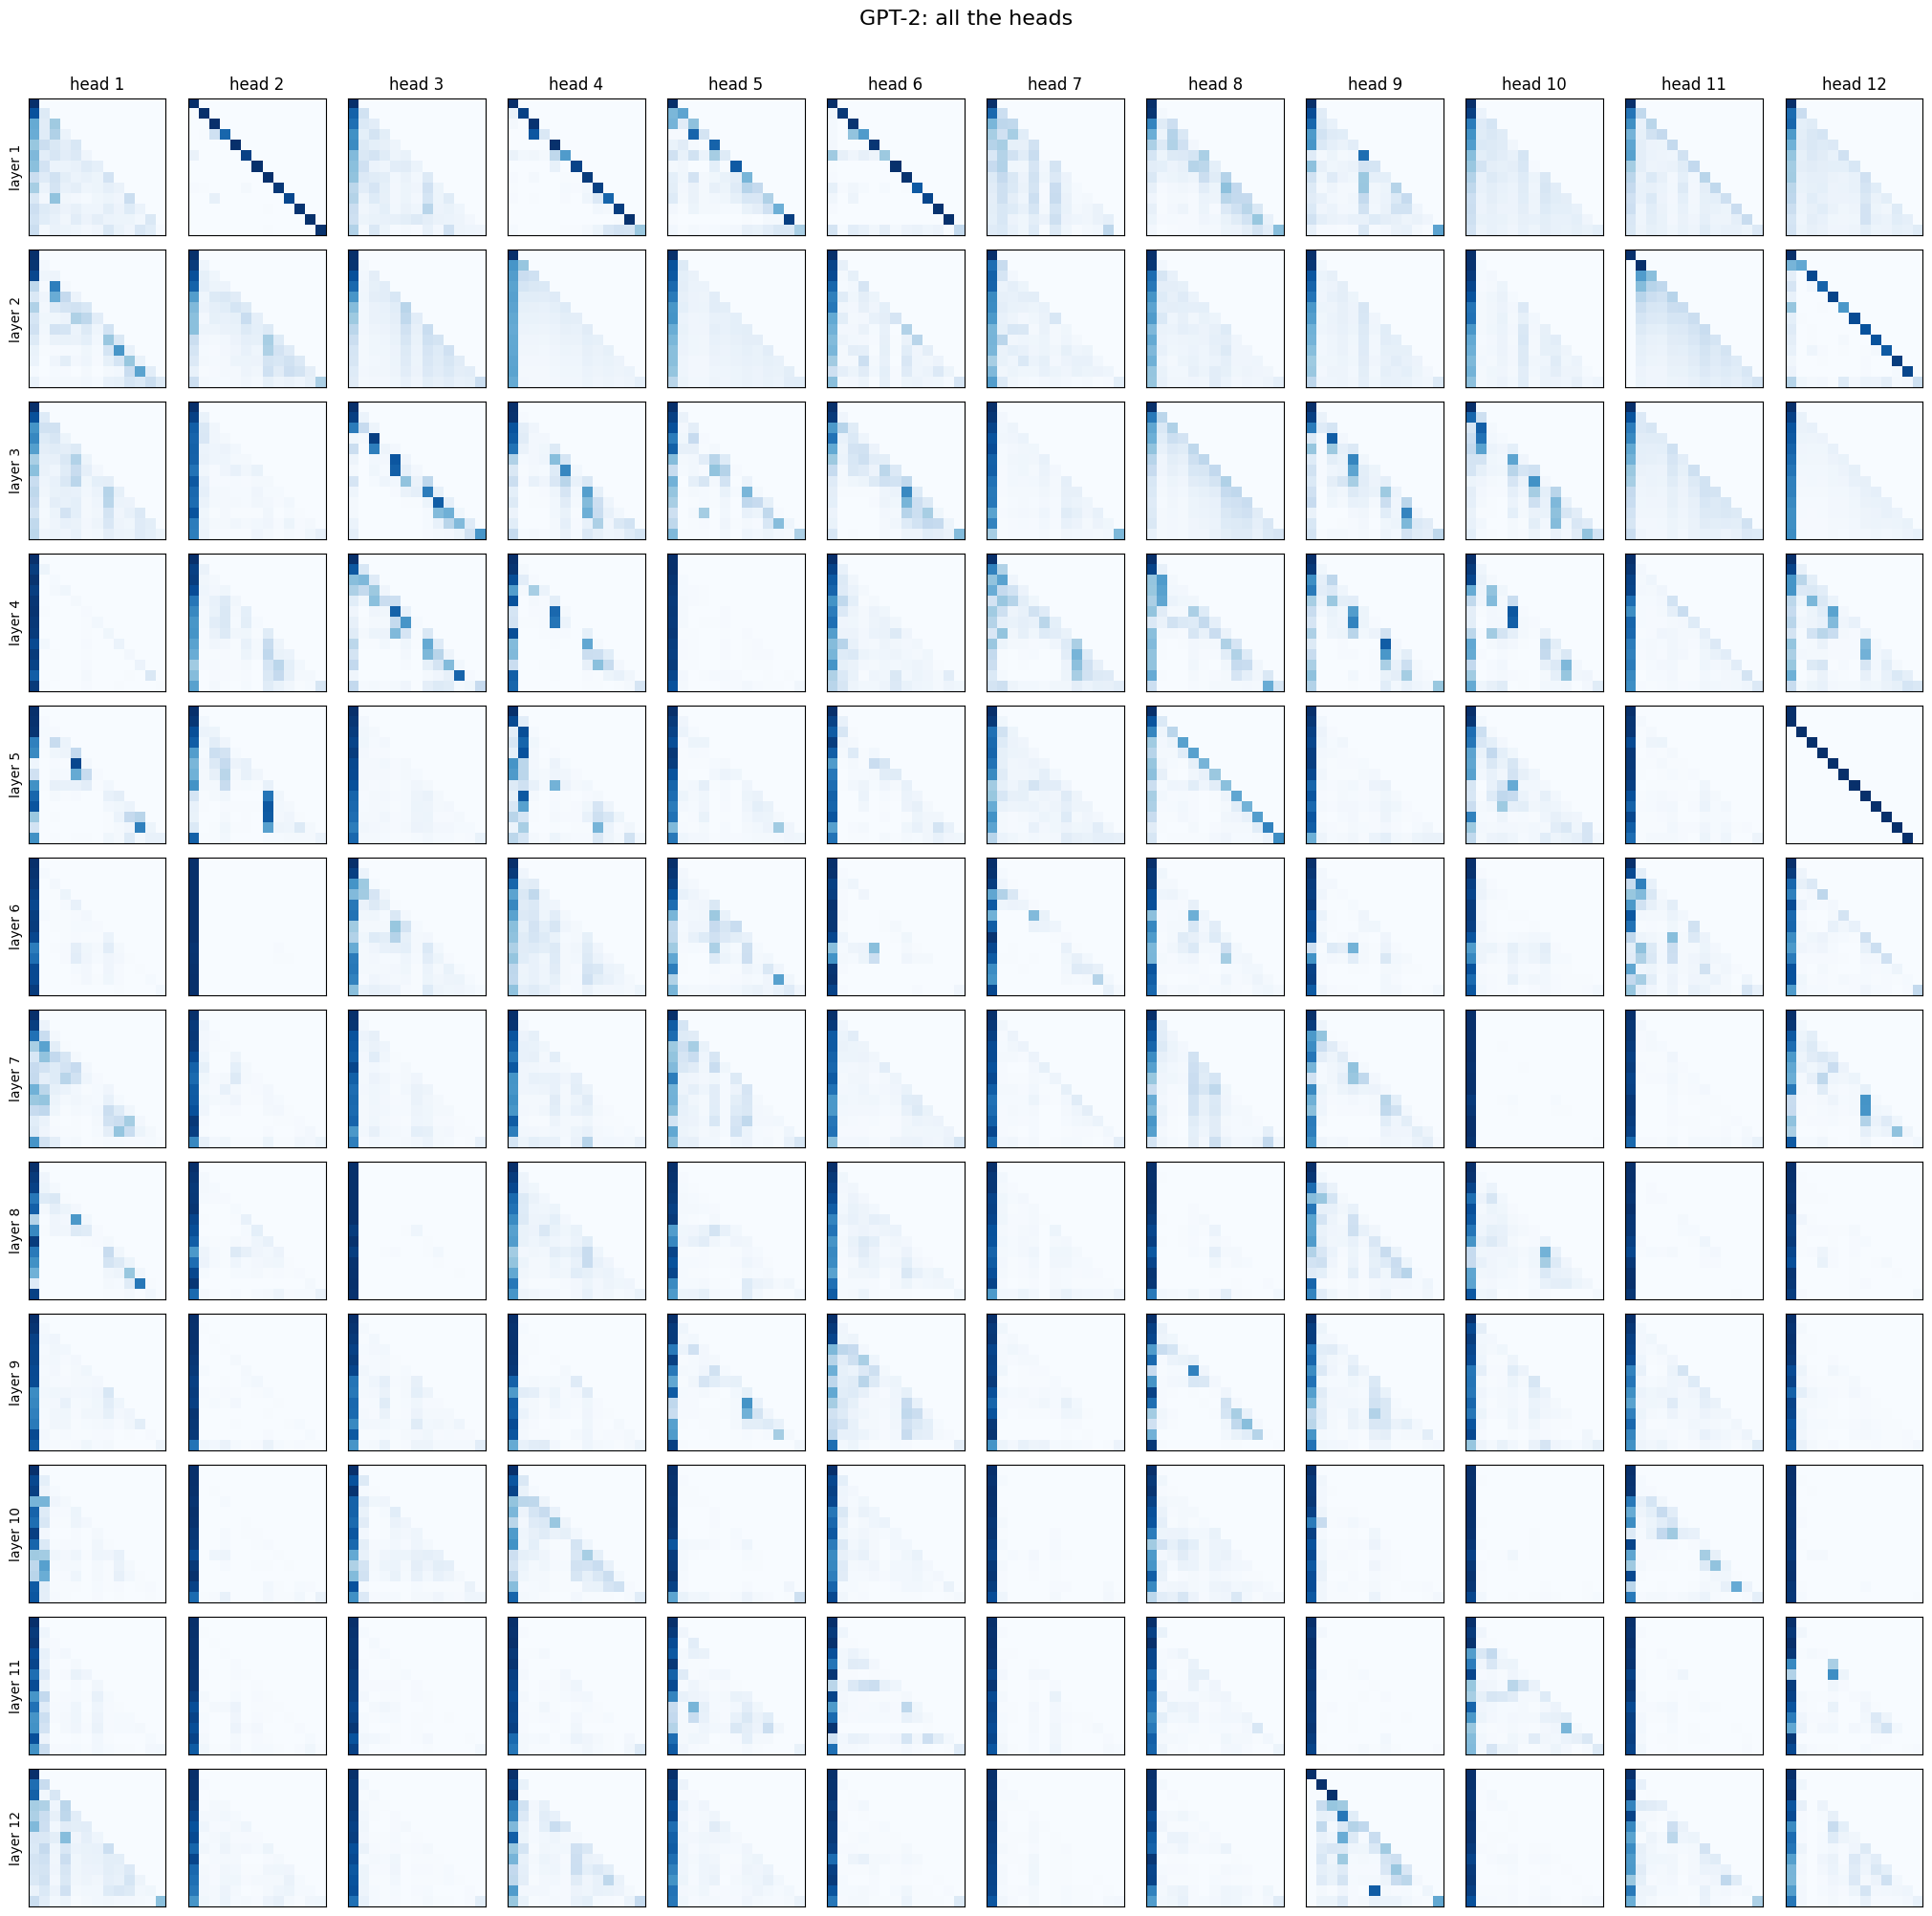

In [19]:
gpt2_tokens, gpt2_attentions = get_attentions("openai-community/gpt2", sentence)
print(gpt2_tokens)

show_all_heads(gpt2_attentions, "GPT-2: all the heads", "gpt2_all_heads")

One head, large.

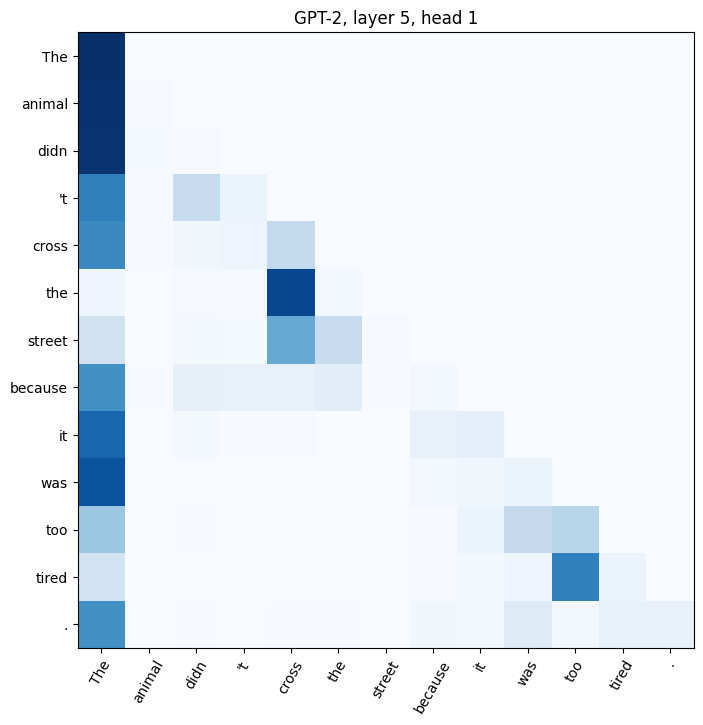

In [20]:
layer, head = 5, 1

show_matrix(gpt2_attentions[layer - 1][0, head - 1].numpy(), gpt2_tokens, gpt2_tokens,
            f"GPT-2, layer {layer}, head {head}", numbers=False)
save_figure(plt.gcf(), f"gpt2_layer{layer}_head{head}")
plt.show()

### 11.2 BERT

The same sentence. Now the maps are full: no causal mask.

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']


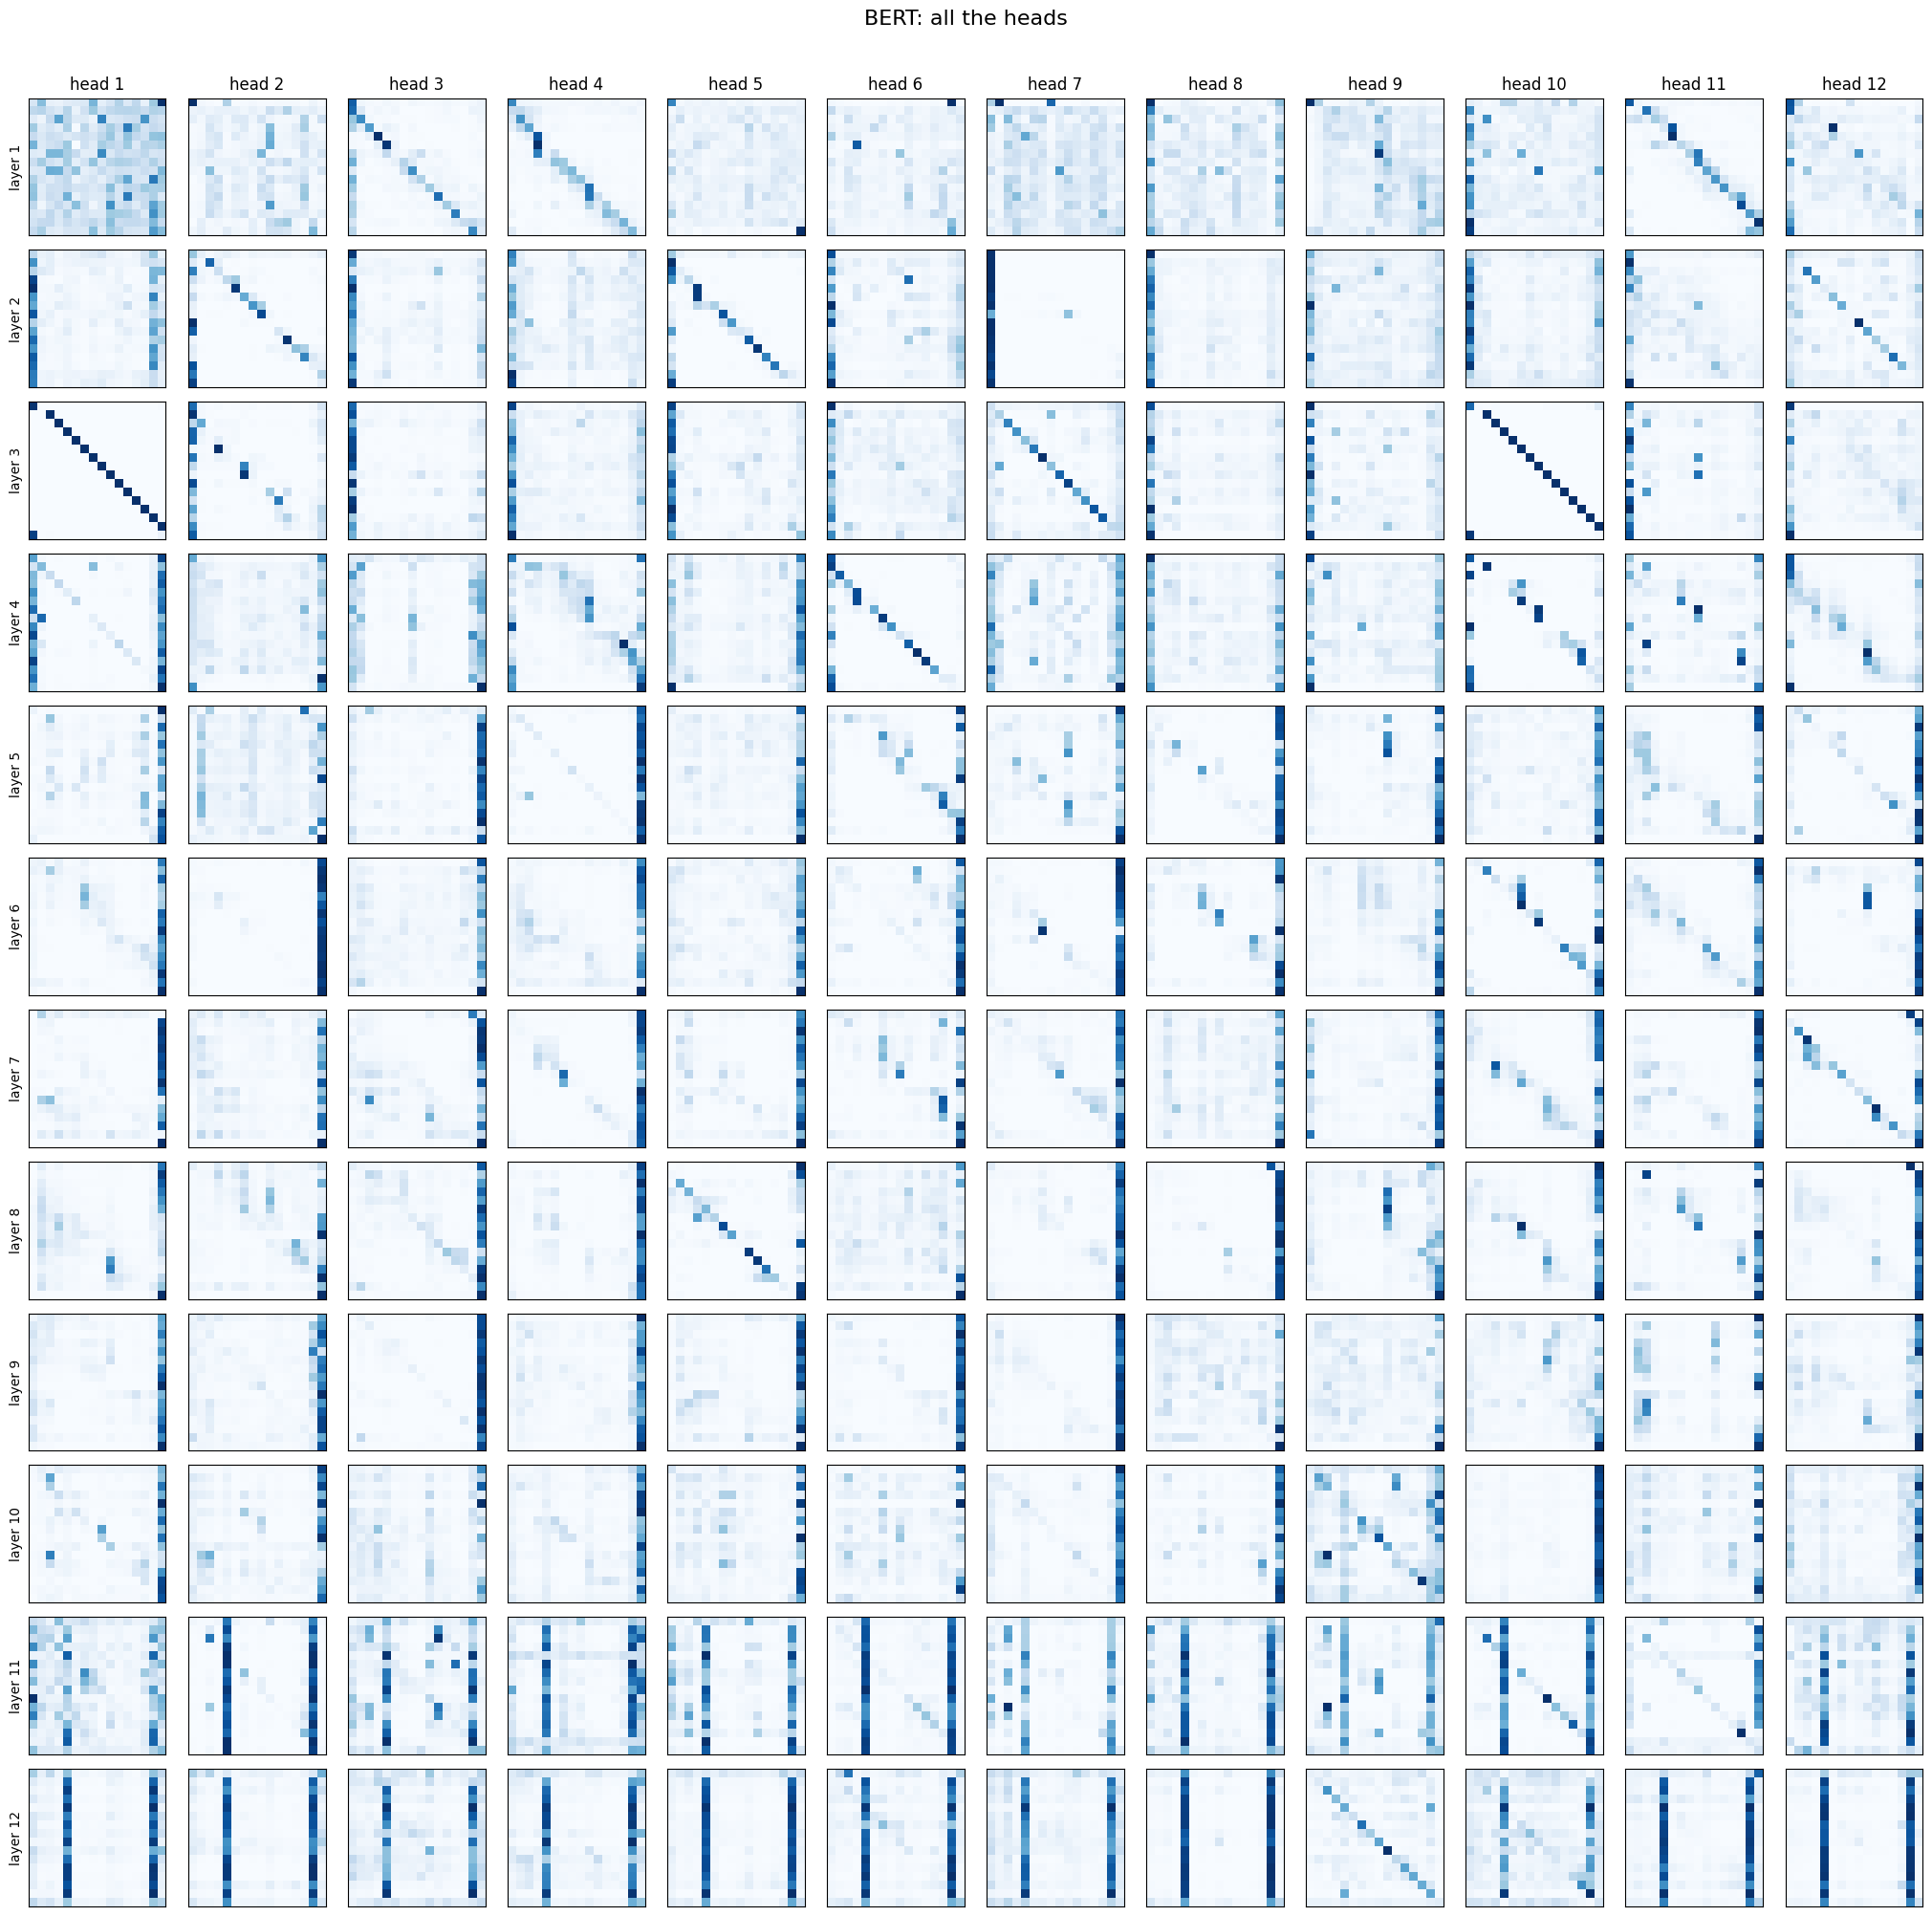

In [21]:
bert_tokens, bert_attentions = get_attentions("google-bert/bert-base-uncased", sentence)
print(bert_tokens)

show_all_heads(bert_attentions, "BERT: all the heads", "bert_all_heads")

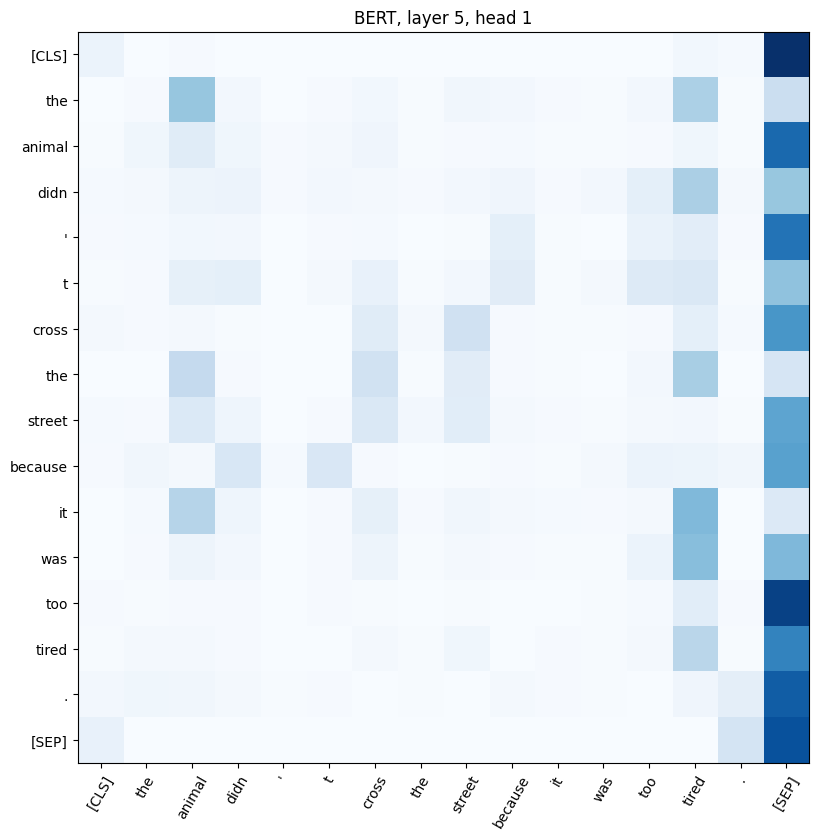

In [22]:
layer, head = 5, 1

show_matrix(bert_attentions[layer - 1][0, head - 1].numpy(), bert_tokens, bert_tokens,
            f"BERT, layer {layer}, head {head}", numbers=False)
save_figure(plt.gcf(), f"bert_layer{layer}_head{head}")
plt.show()

## References

- Clark, K., Khandelwal, U., Levy, O., and Manning, C. D. (2019). What Does BERT Look At? An Analysis of BERT's Attention. *BlackboxNLP Workshop, ACL 2019*.
- Devlin, J., Chang, M.-W., Lee, K., and Toutanova, K. (2019). BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding. *NAACL 2019*.
- Jain, S., and Wallace, B. C. (2019). Attention is not Explanation. *NAACL 2019*.
- Radford, A., Wu, J., Child, R., Luan, D., Amodei, D., and Sutskever, I. (2019). Language Models are Unsupervised Multitask Learners. OpenAI report (not peer-reviewed).
- Vaswani, A., et al. (2017). Attention Is All You Need. *NeurIPS 2017*.
- Vig, J. (2019). A Multiscale Visualization of Attention in the Transformer Model. *ACL 2019, System Demonstrations*.
- Xiao, G., Tian, Y., Chen, B., Han, S., and Lewis, M. (2024). Efficient Streaming Language Models with Attention Sinks. *ICLR 2024*.